In [1]:
import os
import sys

prefix = sys.prefix

# Add the active Conda environment's DLL directories
dll_dirs = [
    os.path.join(prefix, "Library", "bin"),
    os.path.join(prefix, "DLLs"),
]

# Keep handles alive for the lifetime of the kernel
_dll_handles = []

for directory in dll_dirs:
    if os.path.isdir(directory):
        _dll_handles.append(os.add_dll_directory(directory))

# Also put Conda directories at the beginning of PATH
conda_paths = [
    prefix,
    os.path.join(prefix, "Library", "bin"),
    os.path.join(prefix, "Scripts"),
    os.path.join(prefix, "DLLs"),
]

os.environ["PATH"] = os.pathsep.join(
    p for p in conda_paths if os.path.isdir(p)
) + os.pathsep + os.environ.get("PATH", "")

print("Conda DLL directories configured.")

Conda DLL directories configured.


In [1]:
%matplotlib inline

import matplotlib.pyplot as plt

print("Current backend:", plt.get_backend())

Current backend: inline


In [2]:
import numpy as np
import pandas as pd
import joblib
import re

from pathlib import Path
from matplotlib.lines import Line2D

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
from sklearn.metrics.pairwise import paired_cosine_distances

from src.data import study_table, findings_texts, usable_findings, binary_label
from src.embeddings import embedding_path, load_embeddings, embed_texts
from src.edits import sentences, find_sentence

c:\Users\bella\miniconda3\envs\RAI3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Week 2 

### 1 Classifier

In [3]:
# Configuration
FINDING = "pleural_effusion"
TEST_SIZE = 0.30
RANDOM_STATE = 42

Path("models").mkdir(exist_ok=True)


In [4]:
# Load studies, labels and embeddings
studies = study_table().reset_index(drop=True)

embeddings = load_embeddings(
    embedding_path("findings"),
    studies,
)

# Assumes findings_texts(studies) returns aligned texts
texts = findings_texts(studies)

if not isinstance(texts, pd.Series):
    texts = pd.Series(texts)

texts = texts.reset_index(drop=True)

# Use the project's binary labels:
# positive = 1, negative = 0, other labels = missing
y_all = pd.Series(
    binary_label(studies, FINDING)
).reset_index(drop=True)

# Use the same findings eligibility as Week 1.
# Assumes usable_findings returns a boolean mask.
usable = pd.Series(
    usable_findings(studies)
).reset_index(drop=True).astype(bool)

# Keep only eligible studies with clear binary labels
mask = (
    usable
    & y_all.isin([0, 1])
    & studies["patient_id"].notna()
    & texts.notna()
    & texts.astype(str).str.strip().ne("")
)

indices = np.flatnonzero(mask.to_numpy())

X = embeddings[indices]
y = y_all.iloc[indices].astype(int).to_numpy()

groups = (
    studies.iloc[indices]["patient_id"]
    .to_numpy()
)

texts_filtered = texts.iloc[indices].reset_index(drop=True)
studies_filtered = studies.iloc[indices].reset_index(drop=True)

print(f"Total eligible studies: {len(y)}")
print(f"Unique patients: {len(np.unique(groups))}")
print(f"Positive: {np.sum(y == 1)}")
print(f"Negative: {np.sum(y == 0)}")


Total eligible studies: 784
Unique patients: 607
Positive: 646
Negative: 138


In [5]:
# Patient-wise 70/30 split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

# Verify no patient appears in both sets
assert set(groups[train_idx]).isdisjoint(
    set(groups[test_idx])
), "Patient leakage detected!"

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

texts_train = texts_filtered.iloc[train_idx]
texts_test = texts_filtered.iloc[test_idx]

# Verify both classes are represented
assert len(np.unique(y_train)) == 2
assert len(np.unique(y_test)) == 2

print("\nPatient-wise split:")
print(f"Training studies: {len(train_idx)}")
print(f"Held-out studies: {len(test_idx)}")
print(f"Training patients: {len(np.unique(groups[train_idx]))}")
print(f"Held-out patients: {len(np.unique(groups[test_idx]))}")


Patient-wise split:
Training studies: 556
Held-out studies: 228
Training patients: 424
Held-out patients: 183


In [6]:
# Train embedding linear probe
probe = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        solver="liblinear",
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    )),
])
# Fit ONLY on the training set
probe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,768
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [7]:
# Evaluate on original held-out embeddings
test_probs = probe.predict_proba(X_test)[:, 1]
test_preds = probe.predict(X_test)

auc = roc_auc_score(y_test, test_probs)

balanced_acc = balanced_accuracy_score(
    y_test,
    test_preds
)

print("\nOriginal held-out performance:")
print(f"AUROC: {auc:.4f}")
print(f"Balanced accuracy: {balanced_acc:.4f}")



Original held-out performance:
AUROC: 0.9292
Balanced accuracy: 0.8637


In [8]:
# Save frozen model and held-out split

joblib.dump(
    probe,
    "models/pleural_effusion_probe.joblib"
)

np.save(
    "models/pleural_effusion_train_indices.npy",
    indices[train_idx]
)

np.save(
    "models/pleural_effusion_test_indices.npy",
    indices[test_idx]
)

print("\nFrozen classifier and split saved.")



Frozen classifier and split saved.


### 2 Interventions

Interventions:
1) Negation. Replace effusion sentence with "no pleural effusion". Hypothesis: Probability of effusion should drop as there are no longer any findings which describe pleural effusion. TF-IDF should decrease
2) Swap small/trace with large. Hypothesis: Probability of effusion should stay the same. TF-IDF should increase
3) Add atelectasis (compressed lung): Probability of effusion should increase. TF-IDF should increase
4) Change the word effusion with infusion. Hypothesis: Probability of of effusion should go down

In [9]:
def replace_sentence(text, index, new_sentence):
    parts = sentences(text)

    if index is None or index >= len(parts):
        return text, False

    if parts[index] == new_sentence:
        return text, False

    parts[index] = new_sentence
    return " ".join(parts), True


# Negation
def negate_effusion(text):
    """
    Replace affirmative effusion phrases with
    'no pleural effusion' throughout the report.

    Preserves surrounding text.
    """

    pattern = (
        r"\b"
        r"(?:(?:trace|small|moderate|large|mild|tiny|loculated)\s+)?"
        r"(?:(?:left|right|bilateral)\s+)?"
        r"(?:pleural\s+)?effusions?"
        r"\b"
    )

    # Do not modify phrases already explicitly negated
    negative_pattern = re.compile(
        r"\b(?:no|without)\s+(?:pleural\s+)?effusions?\b",
        re.IGNORECASE
    )

    if not re.search(pattern, text, re.IGNORECASE):
        return text, False

    def replace(match):
        # Check the words immediately preceding the match
        preceding = text[max(0, match.start() - 30):match.start()]

        if re.search(r"\b(?:no|without)\s*$", preceding, re.I):
            return match.group(0)

        return "no pleural effusion"

    edited = re.sub(
        pattern,
        replace,
        text,
        flags=re.IGNORECASE
    )

    return edited, edited != text


# Small -> large
def small_to_large(text):
    i = find_sentence(text, r"\beffusions?\b")

    if i is None:
        return text, False

    parts = sentences(text)
    sentence = parts[i]

    # Only change "small" within an effusion sentence
    edited, count = re.subn(
        r"\bsmall\b",
        "large",
        sentence,
        count=1,
        flags=re.IGNORECASE
    )

    if count == 0:
        return text, False

    return replace_sentence(text, i, edited)

# Add atelectasis
def add_atelectasis(text):

    # Avoid duplicating an existing atelectasis mention
    if re.search(
        r"\batelectasis\b",
        text,
        flags=re.IGNORECASE
    ):
        return text, False

    edited = text.rstrip()

    if edited and not edited.endswith("."):
        edited += "."

    edited += " Mild bibasilar atelectasis."

    return edited.strip(), True


# Effusion -> infusion
def effusion_to_infusion(text):
    i = find_sentence(text, r"\beffusions?\b")

    if i is None:
        return text, False

    parts = sentences(text)
    sentence = parts[i]

    edited, count = re.subn(
        r"\beffusion(s?)\b",
        r"infusion\1",
        sentence,
        count=1,
        flags=re.IGNORECASE
    )

    if count == 0:
        return text, False

    return replace_sentence(text, i, edited)

EDIT_FUNCTIONS = {
    "negation": negate_effusion,
    "small_to_large": small_to_large,
    "add_atelectasis": add_atelectasis,
    "effusion_to_infusion": effusion_to_infusion,
}


In [10]:
def apply_edit_to_reports(texts, edit_function):

    records = []

    for text in texts:
        original = str(text)
        edited, applied = edit_function(original)

        records.append({
            "original_text": original,
            "edited_text": edited,
            "edit_applied": applied,
        })

    return pd.DataFrame(records)


edited_datasets = {}

for edit_name, edit_function in EDIT_FUNCTIONS.items():

    df = apply_edit_to_reports(
        texts_test,
        edit_function
    )

    edited_datasets[edit_name] = df

    print(
        f"{edit_name}: "
        f"{df['edit_applied'].sum()} / {len(df)} "
        "reports edited"
    )


negation: 190 / 228 reports edited
small_to_large: 78 / 228 reports edited
add_atelectasis: 148 / 228 reports edited
effusion_to_infusion: 198 / 228 reports edited


In [11]:
for edit_name, df in edited_datasets.items():

    print(f"\n{'=' * 60}")
    print(edit_name)

    examples = df[df["edit_applied"]].sample(
        n=min(5, df["edit_applied"].sum()),
        random_state=42
    )

    for _, row in examples.iterrows():
        print("\nBEFORE:", row["original_text"])
        print("AFTER: ", row["edited_text"])


negation

BEFORE: The heart is mildly enlarged. There is tortuosity of the thoracic aorta and part due to a thoracic scoliosis. There are chronic-appearing bronchitic type changes but cannot exclude acute bronchitis or interstitial pneumonitis. No focal infiltrates, edema or effusions. The bony thorax is intact.
AFTER:  The heart is mildly enlarged. There is tortuosity of the thoracic aorta and part due to a thoracic scoliosis. There are chronic-appearing bronchitic type changes but cannot exclude acute bronchitis or interstitial pneumonitis. No focal infiltrates, edema or no pleural effusion. The bony thorax is intact.

BEFORE: Previously noted pneumothorax is inapparent. Small right pleural effusion with some adjacent atelectasis/consolidation in the posterior basilar segment right lower lobe. Left lung clear. Heart size normal. Multiple minimally displaced right rib fractures are again noted.
AFTER:  Previously noted pneumothorax is inapparent. no pleural effusion with some adjacen

### 3 Measurements

In [12]:
# Original probabilities
X_test = np.asarray(X_test)

# Original probability of pleural effusion
original_probs = probe.predict_proba(X_test)[:, 1]

print("Number of held-out reports:", len(original_probs))
print("Embedding shape:", X_test.shape)

Number of held-out reports: 228
Embedding shape: (228, 768)


In [13]:
# Embed edited text and score with classifier from (1)

# Report per edit: 
# Mean probability of effusion before and after edit
# Flip rate: the fraction of reports where the decision (above or below 0.5) changed
# the representation shift: the mean cosine distance (1 minus the cosine similarity) between the original and the edited embedding

# IMPORTANT:
# embed_findings(texts) must use the SAME BioClinicalBERT model, tokenizer, pooling, and preprocessing as the original embeddings.
HYPOTHESES = {
    "negation": "Decrease",
    "small_to_large": "Approximately unchanged",
    "add_atelectasis": "Increase",
    "effusion_to_infusion": "Decrease",
}

results = []
report_results = {}

for edit_name, edit_function in EDIT_FUNCTIONS.items():

    print(f"\nEvaluating: {edit_name}")

    # 1. Apply edit to all held-out reports
    edited_texts = []
    applicable_indices = []

    for i, text in enumerate(texts_test):

        edited, applied = edit_function(str(text))

        if applied and edited != str(text):
            applicable_indices.append(i)
            edited_texts.append(edited)

    applicable_indices = np.asarray(
        applicable_indices,
        dtype=int
    )

    n = len(applicable_indices)

    if n == 0:
        print("No applicable reports.")
        continue

    # 2. Original embeddings and probabilities
    #    for exactly the applicable reports
    X_before = X_test[applicable_indices]
    p_before = original_probs[applicable_indices]

    # 3. Embed edited texts
    X_after = np.asarray(
        embed_texts(edited_texts)
    )

    assert X_after.shape == X_before.shape, (
        f"Embedding shape mismatch for {edit_name}: "
        f"{X_after.shape} vs {X_before.shape}"
    )

    # 4. Score edited embeddings with frozen probe
    p_after = probe.predict_proba(X_after)[:, 1]

    # 5. Calculate decision flips
    decisions_before = p_before >= 0.5
    decisions_after = p_after >= 0.5

    flip_rate = np.mean(
        decisions_before != decisions_after
    )

    # 6. Calculate representation shift
    cosine_distances = paired_cosine_distances(
        X_before,
        X_after
    )

    mean_cosine_shift = np.mean(cosine_distances)

    # 7. Store summary results
    results.append({
        "Edit type": edit_name,
        "Hypothesis": HYPOTHESES[edit_name],
        "N reports": n,
        "Mean P before": np.mean(p_before),
        "Mean P after": np.mean(p_after),
        "Flip rate": flip_rate,
        "Mean cosine shift": mean_cosine_shift,
    })

    # 8. Store individual report results
    report_results[edit_name] = pd.DataFrame({
        "report_index": applicable_indices,
        "original_text": [
            str(texts_test.iloc[i])
            for i in applicable_indices
        ],
        "edited_text": edited_texts,
        "p_before": p_before,
        "p_after": p_after,
        "delta_probability": p_after - p_before,
        "flipped": (
            decisions_before != decisions_after
        ),
        "cosine_distance": cosine_distances,
    })

    print(f"Applicable reports: {n}")
    print(f"Mean P before: {np.mean(p_before):.4f}")
    print(f"Mean P after:  {np.mean(p_after):.4f}")
    print(f"Flip rate:     {flip_rate:.4f}")
    print(f"Cosine shift:  {mean_cosine_shift:.4f}")



Evaluating: negation


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 19027.64it/s]
[transformers] BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  embedded 32/190
Applicable reports: 190
Mean P before: 0.8008
Mean P after:  0.5594
Flip rate:     0.2737
Cosine shift:  0.0018

Evaluating: small_to_large


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 10476.94it/s]
[transformers] BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  embedded 32/78
Applicable reports: 78
Mean P before: 0.9189
Mean P after:  0.9060
Flip rate:     0.0000
Cosine shift:  0.0003

Evaluating: add_atelectasis


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 11854.71it/s]
[transformers] BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  embedded 32/148
Applicable reports: 148
Mean P before: 0.6677
Mean P after:  0.6932
Flip rate:     0.0203
Cosine shift:  0.0034

Evaluating: effusion_to_infusion


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 33437.48it/s]
[transformers] BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  embedded 32/198
Applicable reports: 198
Mean P before: 0.7703
Mean P after:  0.7006
Flip rate:     0.0859
Cosine shift:  0.0022


In [14]:
results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        "Mean P before": "{:.4f}",
        "Mean P after": "{:.4f}",
        "Flip rate": "{:.2%}",
        "Mean cosine shift": "{:.4f}",
    })
)

results_df.to_csv("intervention_results.csv", index=False)

for edit_name, df in report_results.items():
    df.to_csv(f"intervention_{edit_name}.csv", index=False)

,Edit type,Hypothesis,N reports,Mean P before,Mean P after,Flip rate,Mean cosine shift
0,negation,Decrease,190,0.8008,0.5594,27.37%,0.0018
1,small_to_large,Approximately unchanged,78,0.9189,0.9060,0.00%,0.0003
2,add_atelectasis,Increase,148,0.6677,0.6932,2.03%,0.0034
3,effusion_to_infusion,Decrease,198,0.7703,0.7006,8.59%,0.0022


### 4 Visualizations

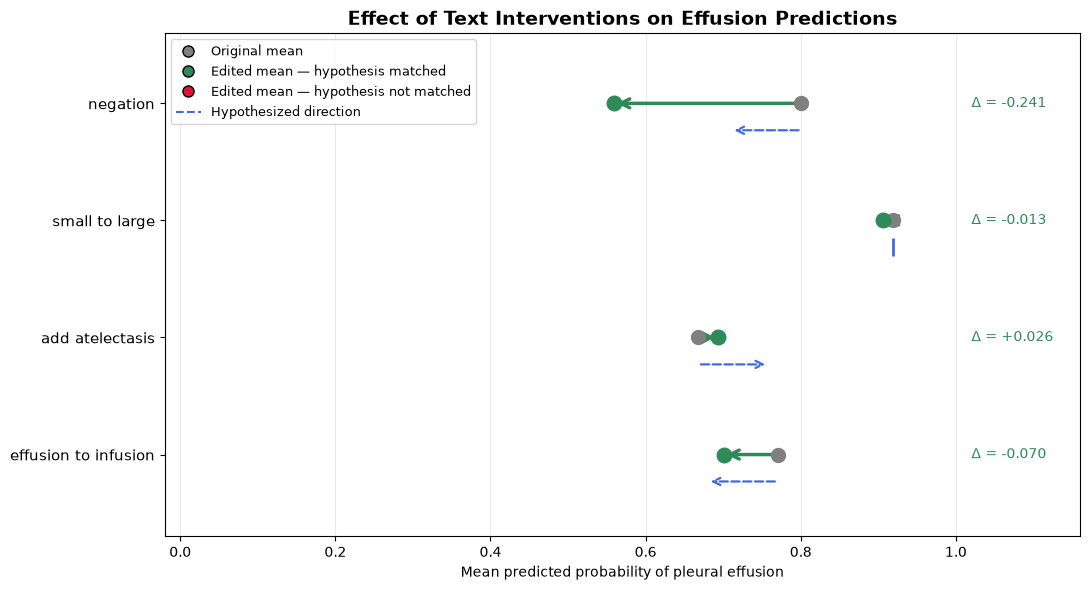

In [18]:
results_df = pd.read_csv("intervention_results.csv")

report_results = {
    name: pd.read_csv(f"intervention_{name}.csv")
    for name in [
        "negation",
        "small_to_large",
        "add_atelectasis",
        "effusion_to_infusion",
    ]
}

# Expected direction for each intervention
expected = {
    "negation": -1,
    "small_to_large": 0,
    "add_atelectasis": 1,
    "effusion_to_infusion": -1,
}

# Tolerance for "approximately unchanged"
tolerance = 0.03

df = results_df.copy()

fig, ax = plt.subplots(figsize=(11, 6))

for i, row in df.iterrows():

    edit = row["Edit type"]
    before = row["Mean P before"]
    after = row["Mean P after"]
    delta = after - before

    direction = expected[edit]

    # Determine whether hypothesis matched
    if direction == 0:
        matched = abs(delta) <= tolerance
    else:
        matched = delta * direction > 0

    color = "seagreen" if matched else "crimson"

    # Original mean
    ax.scatter(
        before, i,
        color="gray",
        s=100,
        zorder=4
    )

    # Actual arrow: before -> after
    ax.annotate(
        "",
        xy=(after, i),
        xytext=(before, i),
        arrowprops=dict(
            arrowstyle="->",
            color=color,
            lw=2.5,
            mutation_scale=16
        ),
        zorder=3
    )

    # Edited mean
    ax.scatter(
        after, i,
        color=color,
        s=110,
        zorder=5
    )

    # Hypothesized direction:
    # dashed arrow just below the actual arrow
    y_expected = i + 0.23

    if direction != 0:
        arrow_length = 0.09 * direction

        # Keep expected arrow within plot limits
        start = np.clip(before, 0.10, 0.90)
        end = start + arrow_length

        ax.annotate(
            "",
            xy=(end, y_expected),
            xytext=(start, y_expected),
            arrowprops=dict(
                arrowstyle="->",
                linestyle="dashed",
                color="royalblue",
                lw=1.6,
                mutation_scale=13
            )
        )
    else:
        ax.scatter(
            before,
            y_expected,
            marker="|",
            color="royalblue",
            s=170,
            linewidths=2
        )

    # Display numerical change
    ax.text(
        1.02, i,
        f"Δ = {delta:+.3f}",
        va="center",
        fontsize=10,
        color=color
    )

ax.set_yticks(range(len(df)))
ax.set_yticklabels(
    df["Edit type"].str.replace("_", " "),
    fontsize=11
)

ax.set_xlim(-0.02, 1.16)
ax.set_xticks(np.linspace(0, 1, 6))
ax.set_xlabel("Mean predicted probability of pleural effusion")
ax.set_title(
    "Effect of Text Interventions on Effusion Predictions",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylim(len(df) - 0.3, -0.6)
ax.grid(axis="x", alpha=0.25)

legend = [
    Line2D([0], [0], marker="o", color="none",
           markerfacecolor="gray", markersize=8,
           label="Original mean"),
    Line2D([0], [0], marker="o", color="none",
           markerfacecolor="seagreen", markersize=8,
           label="Edited mean — hypothesis matched"),
    Line2D([0], [0], marker="o", color="none",
           markerfacecolor="crimson", markersize=8,
           label="Edited mean — hypothesis not matched"),
    Line2D([0], [0], linestyle="dashed",
           color="royalblue",
           label="Hypothesized direction"),
]

ax.legend(
    handles=legend,
    loc="upper left",
    fontsize=9
)

plt.tight_layout()
plt.show()


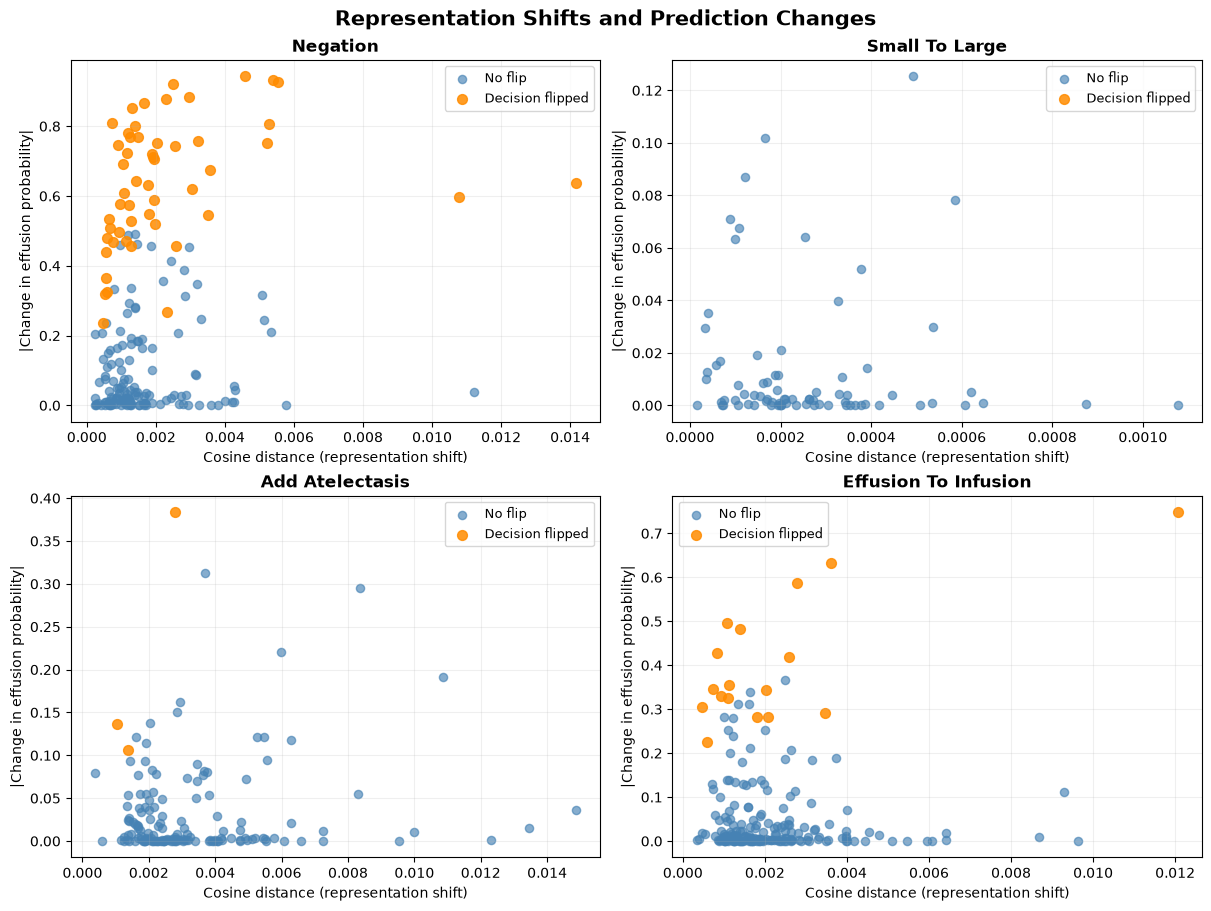

In [20]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 9),
    constrained_layout=True
)

axes = axes.flatten()

edit_names = list(report_results.keys())

for ax, edit_name in zip(axes, edit_names):

    df = report_results[edit_name].copy()

    # Sample up to 100 reports per intervention
    # for a readable visualization
    # if len(df) > 100:
    #     df = df.sample(n=100, random_state=42)

    flipped = df["flipped"].astype(bool)

    # Reports without a decision flip
    ax.scatter(
        df.loc[~flipped, "cosine_distance"],
        df.loc[~flipped, "delta_probability"].abs(),
        color="steelblue",
        alpha=0.65,
        s=35,
        label="No flip"
    )

    # Reports with a decision flip
    ax.scatter(
        df.loc[flipped, "cosine_distance"],
        df.loc[flipped, "delta_probability"].abs(),
        color="darkorange",
        alpha=0.85,
        s=50,
        label="Decision flipped"
    )

    ax.set_title(
        edit_name.replace("_", " ").title(),
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel("Cosine distance (representation shift)")
    ax.set_ylabel("|Change in effusion probability|")

    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)

# Hide unused panels, if any
for ax in axes[len(edit_names):]:
    ax.axis("off")

fig.suptitle(
    "Representation Shifts and Prediction Changes",
    fontsize=15,
    fontweight="bold"
)

plt.show()
